### Aim 1:
#### 1. figures - 1000ms trial accuracy across three classifiers.

In [27]:
# %logstart -r aim1_fig1.py 

Set working directory:

In [1]:
project_path = '/project_data/volume0/tpirnia/data/EEGWS'
results_path = '/data/across_subjects/results/clean/aim-1/'

Data locations:

In [2]:
dt_dfname = 'results_c_avg_w1000_block5-5_DT-CLEAN.csv'
ridge_dfname = 'results_c_avg_w1000_block5-5_ridge-CLEAN.csv'
svm_dfname = 'results_c_avg_w1000_block5-5_svm-CLEAN.csv'

In [3]:
datafiles = [ridge_dfname, svm_dfname, dt_dfname]

In [4]:
exclude_subjects = ['EP24']

In [5]:
figure_name = 'Figure1-Comparison_of_classifier_performance.png'

In [6]:
ttest_fname = project_path + '/data/across_subjects/results/clean/ttest.csv'

Initialize:

In [7]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl
import seaborn as sns

from scipy.stats import ttest_rel

In [8]:
sys.path.append(project_path + '/maybe_repo')
from utils.utils import save_output


In [9]:
from statsmodels.stats.multitest import multipletests
# from scipy.stats import norm


In [10]:
plt.rcParams.update(plt.rcParamsDefault)
%matplotlib inline
plt.style.use('seaborn-darkgrid')
plt.style.use('seaborn-poster')

0. [x] Load data sets
1. Prep data frame
    - [x] Concatenate data sets
    - [x] Identify columns I need: subject, classifier, window, train accuracy, t_500
    - [x] Rename column names
2. Stats for plot: groupby and average by classifier.
    - [x] How to add SE
    - [x] How to include significance.
3. [x] Plot.

##### 0. Load Data Sets:

In [11]:
main_df = []
for _fname in datafiles:
    # load file
    _df = pd.read_csv((project_path
                          + results_path
                          + _fname),
                     )
    # add to list
    main_df.append(_df)

##### 1. Prep Data Frame

    - Concatenate data sets

In [12]:
# concatenate
main_df = pd.concat(main_df,
                    ignore_index=True)
main_df.reset_index(inplace=True, 
                    drop=True)

    - Update columns:

In [13]:
col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             't_500': 'Test Accuracy',
            }
main_df.rename(columns=col_renames,
               inplace=True)

    - Remove Subject EP24

In [14]:
main_df = main_df[~main_df['Subject'].isin(exclude_subjects)]
main_df.reset_index(inplace=True,
                    drop=True)

In [15]:
main_df

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,ridge,1000,0,0,0.665000,0.666667
1,EP05,ridge,1000,0,0,0.578333,0.650000
2,EP06,ridge,1000,0,0,0.721667,0.716667
3,EP07,ridge,1000,0,0,0.933333,0.916667
4,EP09,ridge,1000,0,0,0.583333,0.616667
...,...,...,...,...,...,...,...
79,EP29,decisiontree,1000,500,1,0.586667,0.666667
80,EP30,decisiontree,1000,500,1,0.606667,0.483333
81,EP31,decisiontree,1000,500,1,0.570000,0.500000
82,EP32,decisiontree,1000,500,1,0.550000,0.433333


    - Categorize subjects

In [18]:
# change subjects to ordered type
subjects = main_df['Subject'].unique()
_cattype = pd.api.types.CategoricalDtype(categories=subjects, 
                                         ordered=True)
main_df['Subject']=main_df['Subject'].astype(_cattype)

    - Rename Classifiers

In [19]:
clfs = {'ridge':'Ridge Classifer', 
        'svm':'SVM', 
        'decisiontree':'Decision Tree'}
for _c in clfs:
    _inds = (main_df['Classifier'] == _c)
    main_df.loc[_inds,'Classifier'] = clfs[_c]

In [72]:
_cattype = pd.api.types.CategoricalDtype(categories=list(clfs.values()),
                                         ordered=True)
main_df['Classifier'] = main_df['Classifier'].astype(_cattype)

    - Preview DataFrame

In [20]:
main_df.head(5)

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,Ridge Classifer,1000,0,0,0.665000,0.666667
1,EP05,Ridge Classifer,1000,0,0,0.578333,0.650000
2,EP06,Ridge Classifer,1000,0,0,0.721667,0.716667
3,EP07,Ridge Classifer,1000,0,0,0.933333,0.916667
4,EP09,Ridge Classifer,1000,0,0,0.583333,0.616667


##### 3. Plot Results

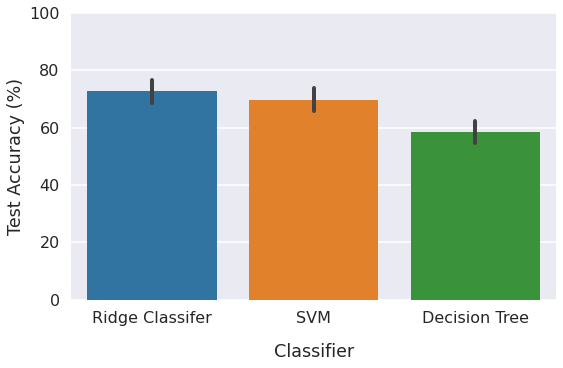

In [18]:
# Test Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Test Accuracy',
                 x='Classifier',
                 data=main_df,
                 ax=_ax, 
                 errwidth=4,
                 ci=95)

locs, _ = plt.yticks()
_ax.xaxis.labelpad = 17
_ax.set(ylabel='Test Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)))

plt.savefig((project_path 
             + results_path 
             + figure_name),
            dpi=450, 
            bbox_inches = "tight")
plt.show()

    - Create train/test DataFrame and plot

In [21]:
# Dataframe for train/test classification 
_df = main_df.melt(id_vars=['Subject',
                            'Classifier',
                            'Trial Length',
                            'step',
                            'w_train'],
                   var_name='Performance',
                   value_name='Accuracy')

_inds_tr, _inds_te = (_df['Performance'] == 'Train Accuracy'),(_df['Performance'] == 'Test Accuracy')
_df.loc[_inds_tr,'Performance'] = 'Train'
_df.loc[_inds_te,'Performance'] = 'Test'

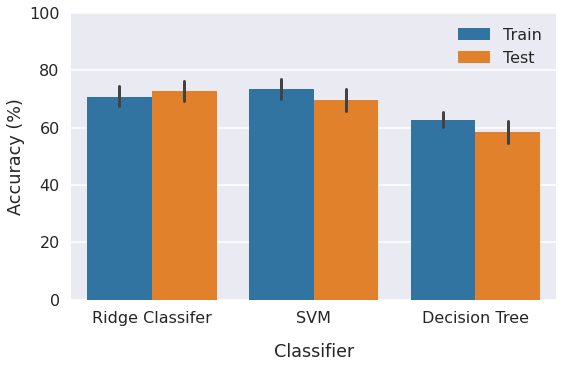

In [20]:
# Train and test Accuracy per classifier for full trial length (cue to 1000ms)
_figdims = (8.7, 5.27)
_fig, _ax = plt.subplots(figsize=_figdims)
_g = sns.barplot(y='Accuracy',
                 x='Classifier',
                 hue='Performance',
                 data=_df,
                 ax=_ax, 
                 errwidth=3,
                 ci=95)

locs, _ = plt.yticks()
_ax.xaxis.labelpad = 17
_ax.set(ylabel='Accuracy (%)', 
        ylim=[0,1],
        yticks=locs, 
        yticklabels=list(map(int,locs*100)))
plt.gca().legend().set_title('')
plt.savefig((project_path 
             + results_path 
             + figure_name[:-4]
             + '_traintest.png'),
            dpi=450, 
            bbox_inches = "tight")
plt.show()

#### Descriptive statistics for performance:

In [22]:
# make df of descriptive statistics
stat_df = main_df.drop(columns=['step',
                                'w_train',
                                'Trial Length'],
                      ).groupby(by=('Classifier'),
                               ).agg(['min', 'max','mean','std','sem','var']) * 100

In [23]:
print(stat_df.transpose().to_latex(float_format="%.2f"))

\begin{tabular}{llrrr}
\toprule
              & Classifier &  Ridge Classifer &   SVM &  Decision Tree \\
\midrule
Train Accuracy & min &            55.50 & 60.17 &          52.17 \\
              & max &            93.33 & 92.83 &          82.17 \\
              & mean &            70.85 & 73.36 &          62.65 \\
              & std &             9.76 &  9.41 &           7.39 \\
              & sem &             1.84 &  1.78 &           1.40 \\
              & var &             0.95 &  0.89 &           0.55 \\
Test Accuracy & min &            56.67 & 50.00 &          40.00 \\
              & max &            91.67 & 91.67 &          80.00 \\
              & mean &            72.68 & 69.76 &          58.39 \\
              & std &            10.40 & 10.77 &          10.15 \\
              & sem &             1.96 &  2.04 &           1.92 \\
              & var &             1.08 &  1.16 &           1.03 \\
\bottomrule
\end{tabular}



In [23]:
# T-test by classifier pairs
ind_cl = {'svm':(main_df['Classifier'] == 'SVM'),
          'ridge': (main_df['Classifier'] == 'Ridge Classifer'),
          'DT': (main_df['Classifier'] == 'Decision Tree'),
         }
t_ridge_svm = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['svm'],'Test Accuracy'].values)
t_ridge_DT = ttest_rel(main_df.loc[ind_cl['ridge'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['DT'],'Test Accuracy'].values)
t_svm_DT = ttest_rel(main_df.loc[ind_cl['svm'],'Test Accuracy'].values,
                        main_df.loc[ind_cl['DT'],'Test Accuracy'].values)
rnd_fn = lambda x: np.round(x, decimals=2)
print('Ridge v. SVM:',
      [rnd_fn(t_ridge_svm[0]),np.round(t_ridge_svm[1],decimals=4)],
      '\nRidge v. DT:',
      [rnd_fn(t_ridge_DT[0]),np.round(t_ridge_DT[1],decimals=10)],
      '\nSVM v. DT:',
      [rnd_fn(t_svm_DT[0]),np.round(t_svm_DT[1],decimals=8)])

Ridge v. SVM: [3.18, 0.0037] 
Ridge v. DT: [8.99, 1.3e-09] 
SVM v. DT: [6.92, 1.9e-07]


In [24]:
save_output(ttest_fname, ['Ridge','SVM']+ list(t_ridge_svm), sep=',')
save_output(ttest_fname, ['Ridge','DT']+ list(t_ridge_DT), sep=',')
save_output(ttest_fname, ['SVM','DT']+ list(t_svm_DT), sep=',')

In [25]:
Save output as a temporary notebook data csv
main_df_out = project_path + '/data/across_subjects/results/tmp_notebook_data/aim1_fig1_main_df.csv'
# main_df.to_csv(main_df_out, index=False)

In [19]:
ridge_perm = '/data/across_subjects/results/results_c_avg_w1000_s100_block5-5_ridge_perm500_.csv'

In [20]:
ridgep_df =  pd.read_csv((project_path
                          + ridge_perm),)
ridgep_df.head(4)

,subject,classifier,window,step,w_train,permutation,fold,train_accuracy,t_0,t_500
0,EP07,ridge,1000,500,1,0,1.0,0.941667,0.5,0.416667
1,EP07,ridge,1000,500,1,1,1.0,0.941667,0.5,0.416667
2,EP07,ridge,1000,500,1,2,1.0,0.941667,0.5,0.583333
3,EP07,ridge,1000,500,1,3,1.0,0.941667,0.5,0.083333


In [21]:
ridgep_df.subject.unique()

array(['EP07', 'EP25', 'EP13', 'EP10', 'EP12', 'EP31', 'EP14', 'EP28',
       'EP18', 'EP20', 'EP06', 'EP19', 'EP22', 'EP16', 'EP03', 'EP23',
       'EP05', 'EP11', 'EP21', 'EP26', 'EP09', 'EP30', 'EP33', 'EP17',
       'EP32', 'EP27', 'EP15', 'EP29'], dtype=object)

In [22]:
main_df['permutation']=-1

In [23]:
col_renames={'subject': 'Subject',
             'classifier':'Classifier', 
             'window': 'Trial Length',
             'train_accuracy':'Train Accuracy', 
             't_500': 'Test Accuracy',
            }
ridgep_df.rename(columns=col_renames,
               inplace=True)
ridgep_df[~ridgep_df['Subject'].isin(exclude_subjects)]

ridgep_df.drop(columns=['t_0'],inplace=True)
ridgep_df.reset_index(inplace=True,
                    drop=True)


In [25]:
ridgep_df = ridgep_df.groupby(as_index=False, by=['Subject','permutation']).mean()

In [38]:
len(ridgep_df['Test Accuracy'].values)

14000

In [39]:
from scipy.stats import norm
import numpy as np
from statsmodels.stats.multitest import multipletests

In [155]:
pval = y2[0][1]#1-norm.cdf(ridgep_df['Test Accuracy'].values) # right-sided test
# count P-values < 0.05
# output: 460
print(len(pval[np.where(pval<0.05)]))

# Bonferroni correction
# Get Bonferroni corrected P-value, which is 0.0001
bf_p = 0.05/14000 
# count P-values < bf_p
# output: 126
print(len(pval[np.where(pval<bf_p)]))

# Benjamini and Hochberg FDR at alpha=0.05
y=multipletests(pvals=pval, alpha=0.05, method="fdr_bh")
# output: 450
print(len(y[1][np.where(y[1]<0.05)]))  # y[1] returns corrected P-vals (array)

1
1
1


In [156]:
y2[0][1]

array([4.52609096e-165])

In [47]:
from scipy import stats
print(stats.ttest_1samp(ridgep_df['Test Accuracy'].values, 0.5))

Ttest_1sampResult(statistic=3.8806512861829443, pvalue=0.00010465463738410636)


In [49]:
np.mean(ridgep_df['Test Accuracy'].values)
np.std(ridgep_df['Test Accuracy'].values)

0.09524198373014187

In [54]:
ridgep_df.groupby(by=['Subject'])['Test Accuracy'].agg(['mean','std'])

,mean,std
Subject,,
EP03,0.505533,0.086229
EP05,0.500733,0.074263
EP06,0.503800,0.091652
EP07,0.505200,0.132838
EP09,0.503667,0.081581
EP10,0.503133,0.126235
EP11,0.501800,0.064933
EP12,0.506067,0.092786
EP13,0.505733,0.133410


In [55]:
subjects

array(['EP03', 'EP05', 'EP06', 'EP07', 'EP09', 'EP10', 'EP11', 'EP12',
       'EP13', 'EP14', 'EP15', 'EP16', 'EP17', 'EP18', 'EP19', 'EP20',
       'EP21', 'EP22', 'EP23', 'EP25', 'EP26', 'EP27', 'EP28', 'EP29',
       'EP30', 'EP31', 'EP32', 'EP33'], dtype=object)

In [58]:
ta = 'Test Accuracy'


In [73]:
main_df['Classifier'].unique()

['Ridge Classifer', 'SVM', 'Decision Tree']
Categories (3, object): ['Ridge Classifer' < 'SVM' < 'Decision Tree']

In [75]:
main_df

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy
0,EP03,Ridge Classifer,1000,0,0,0.665000,0.666667
1,EP05,Ridge Classifer,1000,0,0,0.578333,0.650000
2,EP06,Ridge Classifer,1000,0,0,0.721667,0.716667
3,EP07,Ridge Classifer,1000,0,0,0.933333,0.916667
4,EP09,Ridge Classifer,1000,0,0,0.583333,0.616667
...,...,...,...,...,...,...,...
79,EP29,Decision Tree,1000,500,1,0.586667,0.666667
80,EP30,Decision Tree,1000,500,1,0.606667,0.483333
81,EP31,Decision Tree,1000,500,1,0.570000,0.500000
82,EP32,Decision Tree,1000,500,1,0.550000,0.433333


In [128]:
main_df[ta][(main_df['Subject']=='EP07' )]


3    0.916667
Name: Test Accuracy, dtype: float64

In [82]:
ridgep_df[ta][ridgep_df['Subject']==subject].values

array([0.5       , 0.63333333, 0.5       , 0.4       , 0.46666667,
       0.56666667, 0.33333333, 0.6       , 0.53333333, 0.5       ,
       0.36666667, 0.5       , 0.66666667, 0.53333333, 0.6       ,
       0.53333333, 0.23333333, 0.46666667, 0.46666667, 0.53333333,
       0.33333333, 0.43333333, 0.56666667, 0.43333333, 0.4       ,
       0.43333333, 0.56666667, 0.4       , 0.53333333, 0.36666667,
       0.53333333, 0.56666667, 0.56666667, 0.36666667, 0.56666667,
       0.5       , 0.36666667, 0.4       , 0.5       , 0.6       ,
       0.7       , 0.63333333, 0.43333333, 0.46666667, 0.46666667,
       0.43333333, 0.63333333, 0.36666667, 0.6       , 0.43333333,
       0.3       , 0.7       , 0.56666667, 0.3       , 0.56666667,
       0.6       , 0.46666667, 0.5       , 0.33333333, 0.5       ,
       0.43333333, 0.66666667, 0.43333333, 0.4       , 0.53333333,
       0.43333333, 0.53333333, 0.56666667, 0.46666667, 0.5       ,
       0.63333333, 0.43333333, 0.46666667, 0.46666667, 0.4    

In [120]:
main_df[(main_df['Subject']=='EP06' )&(main_df['Classifier']=='Ridge Classifier')]

,Subject,Classifier,Trial Length,step,w_train,Train Accuracy,Test Accuracy


In [ ]:
ta = 'Test Accuracy'
y2=[]
for subject in subjects:
    rvs1 = ridgep_df[ta][ridgep_df['Subject']==subject].values
    rvs2 = main_df[ta][(main_df['Subject']==subject)].values
    print(subject,':',stats.ttest_1samp(rvs1, rvs2))
    y2.append(stats.ttest_1samp(rvs1, rvs2))

rvs1 = ridgep_df[ta].values
rvs2 = main_df[ta].values
y = stats.ttest_1samp(rvs1, rvs2)
print(subject,':',stats.ttest_1samp(rvs1, rvs2))

In [33]:
len(np.arange(400, 1001 - 50, 10))

56

In [32]:
print(" ".join(map(str,list(np.arange(400, 1001 - 50, 10)))))

400 410 420 430 440 450 460 470 480 490 500 510 520 530 540 550 560 570 580 590 600 610 620 630 640 650 660 670 680 690 700 710 720 730 740 750 760 770 780 790 800 810 820 830 840 850 860 870 880 890 900 910 920 930 940 950


In [20]:
import pingouin as pg

ModuleNotFoundError: No module named 'pingouin'

In [171]:
res = pg.rm_anova(dv='Test Accuracy', within='Classifier', subject='Subject', data=df_main, detailed=True)


NameError: name 'pg' is not defined

In [146]:
[np.where(y[1]<0.05)]

[(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
         17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]),)]

__________
__________

##### Things that didn't work.

In [ ]:
main_df['Subject']=main_df['Subject'].astype('category')

In [ ]:
main_df.loc[:,'Subject']

In [ ]:
main_df.

In [ ]:
main_df['Subject'].astype(_cattype)

In [ ]:
main_df.loc[:,'Subject'] = main_df['Subject'].astype(_cattype)

In [ ]:
# _ax.set(ylim=[0,1])
# locs, _ = plt.yticks()
# plt.yticks(locs, list(map(int,locs*100)))

# # xticks = ['cue-locked\n$t_{cue}[0, 1]$','response-locked\n$t_{res}=[-.5, .5]$']